# F03.03 · Contexto y normalización por paciente: ¿ayuda mirar más atrás?

> 🧭 **En 30 segundos**
> - **Para qué:** la línea base de F03.02 juzga cada ventana de 4 s **sola** y se queda en el azar al predecir (aunque **detecta** bien la crisis). Aquí se prueban las dos palancas más prometedoras **antes** de construir la red: (1) dar **contexto**, es decir, mirar también los segundos de justo antes, y (2) comparar a **cada paciente consigo mismo**.
> - **Entra:** las ventanas de **F03.01**, la señal de **F02.02** (para leer el contexto) y los modelos y la nota de **F03.02** → **Sale:** la nota en 🟡 dev para cada contexto (4, 8, 16, 32 y 60 s en el modelo general), con y sin normalización por paciente, por grupo de crisis, y **qué contexto y normalización hereda la red** (F03.04).
> - **Idea clave:** la ventana sigue siendo de **4 s** (las ausencias y la Fase 4 la necesitan así). El contexto se añade **encima**, con un máximo distinto según el tipo de crisis.

> 📍 **Dónde estamos: Fase 3 · notebook 3 (F03.03).** F03.02 dejó el suelo (AUC ≈ 0,54) y comprobó que la cadena de datos funciona (detectar la crisis da 0,80). La red neuronal pasa a ser **F03.04**.

> 🔄 **Es dinámico.** Lee lo que dejaron F03.01 y F03.02; las cifras, la decisión y las conclusiones salen de los datos al ejecutarlo.

> 🔒 **Regla de oro de la Fase 3: aquí no se mira 🟢 eval.** Todo se decide con 🟡 dev.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Piensa en cómo mira un médico la **tensión arterial**:

1. **Una medida suelta dice poco.** 14 de máxima puede ser normal en una persona y alto en otra. → Es lo que hacía F03.02: juzgar **una** ventana de 4 s, sola. Salió casi el azar.
2. **Hay que compararla con lo normal en esa persona.** "Para ti, que sueles tener 11, un 14 es alto". → **Normalizar por paciente** (§6): restar a cada paciente su valor habitual.
3. **Y mirar la evolución del último rato.** "Lleva media hora subiendo". → **El contexto** (§3-§5): mirar también los segundos de antes de la ventana.

Este notebook prueba esas dos ideas, **por separado y juntas**, con los mismos modelos de F03.02. Se responde a tres preguntas:

| Pregunta | Dónde se responde |
|---|---|
| ¿Ayuda mirar más atrás? ¿Cuánto (8, 16, 32, 60 s)? | §7 (figura principal) |
| ¿Ayuda comparar a cada paciente consigo mismo? ¿Sigue ayudando si la "calibración" se hace solo con momentos tranquilos? | §7 y §9 (prueba de robustez) |
| ¿La mejora es predicción, o el modelo reconoce la grabación? | §10 (control de sesión) |
| ¿Qué recibe la red de F03.04? | §9 (recuadro dorado), §10 y §14 (resumen de todo) |

## El recorrido de este notebook

![El recorrido del notebook F03.03](img/mapa_notebook_03.png)

👀 **Qué enseña.** Los seis pasos, en orden. Los dos en rojo son los importantes: **medir** cada contexto con y sin normalización por paciente (§7) y **decidir** qué hereda la red (§8-§9). Abajo, la regla para comparar de forma justa: el contexto de 4 s (la línea base de F03.02) se vuelve a medir con **las mismas ventanas** que los demás.

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Contexto** | Los segundos que acaban donde acaba la ventana. Con 60 s de contexto, el modelo ve la ventana actual y las 14 de 4 s de justo antes. Ver §3 |
| **Contexto completo** | Que el tramo empiece lo bastante antes de la ventana como para tener todo su contexto. Las ventanas sin él no se usan (en ninguna clase) |
| **Media / variación / cambio** | Cómo se resume el contexto de cada característica: su valor típico, cuánto se ha movido y cuánto se aparta lo de ahora de lo de antes. Ver §5 |
| **Normalización por paciente** | Expresar cada número respecto a lo normal en ese paciente (restar su mediana). Ver §6 |
| **Calibración** | Lo que haría una app al empezar: grabar unos minutos del paciente para saber cuál es su "normal" |
| **Calibración tranquila** | La calibración hecha **solo** con momentos tranquilos (💤) del paciente, sin que sus ⏳ influyan. Es la prueba de que la mejora no es un efecto de cómo se calibra. Ver §6 |
| **Robustez** | Que un resultado se mantenga al cambiar un detalle que no debería importar. Si se cae, el resultado era frágil |
| **Diferencia emparejada** | Comparar dos modelos con las mismas ventanas y los mismos sorteos de pacientes. Su intervalo dice si una mejora es real o casualidad. Ver §9 |
| **AUC-ROC** | La nota: 0,5 = azar, 1 = perfecto (F03.02 §5) |

## 0. El parámetro: qué conjunto se usa

`general` es el modelo principal. Para las ausencias, `grupo_ausencia` (antes hay que ejecutar F03.01 y F03.02 con ese conjunto). Los contextos que se prueban dependen del conjunto (§2).

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill cambiando solo este valor.)*

> **`CONJUNTO` se fija en un solo sitio para toda la Fase 3:** `tfm_comun/prediccion/estudio.py` (`CONJUNTO_ESTUDIO`). Aquí se deja en `None`; solo se pone otro valor para una prueba puntual (o desde papermill). Los resultados de cada conjunto van a su carpeta: `outputs/fase_03/<conjunto>/`.

In [1]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3); se puede poner otro aquí

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar que están instaladas las librerías (las mismas que en F03.02).

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_CONTEXTO
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_CONTEXTO)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características


Todo lo necesario está instalado.


In [3]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
from functools import partial
import re
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import xgboost
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_03, RUTA_SENALES, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.configuracion import leer_configuracion
from tfm_comun.senal.bandas import BANDAS_HZ
from tfm_comun.senal.montaje import CANALES_TCP
from tfm_comun.red.paquetes import cargar_paquete
from tfm_comun.prediccion.caracteristicas import nombres_caracteristicas
from tfm_comun.prediccion.almacen_caracteristicas import caracteristicas_al_dia, guardar_caracteristicas, cargar_caracteristicas
from tfm_comun.prediccion.contextos.duracion import contextos_del_conjunto, preictal_del_conjunto_s, ventanas_por_contexto
from tfm_comun.prediccion.contextos.disponibilidad import con_contexto_completo, inicios_necesarios, clave
from tfm_comun.prediccion.contextos.calculo import caracteristicas_de_inicios
from tfm_comun.prediccion.contextos.indices import cubo_contexto
from tfm_comun.prediccion.contextos.resumen import resumir_contexto, nombres_contexto
from tfm_comun.prediccion.normalizacion_paciente import normalizar_por_paciente, normalizar_con_calibracion
from tfm_comun.prediccion.validacion import rondas_validacion
from tfm_comun.prediccion.linea_base import NOMBRES_MODELO, entrenar, puntuar
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo, diferencia_auroc_con_intervalo
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_por_paciente
from tfm_comun.prediccion.evaluacion.sensibilidad import sensibilidad_con_especificidad
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos
from tfm_comun.visual.colores import COLORES_PERIODO, COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, xgboost)

# El conjunto: si la celda de parámetros lo deja en None, el de tfm_comun/prediccion/estudio.py
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)


Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
xgboost     3.4.1


## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" del notebook y leer lo que dejaron F03.01 y F03.02.
>
> 🤔 **Por qué:** los modelos y sus hiperparámetros son **los de F03.02** (no se vuelven a ajustar): así, si la nota cambia, es por el contexto o la normalización, no por haber probado más cosas.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `CONTEXTOS` | según el conjunto | Segundos de contexto que se prueban: los de `[4, 8, 16, 32, 60]` que no pasan del **preictal** del conjunto (`tfm_comun/prediccion/contextos/`; antes, un tercio). El contexto puede empezar antes de la zona ⏳, como el clip de Tang et al. (2022): la etiqueta la da la ventana actual. Modelo general (3 min, 120 s de preictal) y umbral de 2 min: hasta 60 s. Ausencias (50 s): hasta 32 s. |
| `NORMALIZACIONES` | `['ninguna', 'por_paciente', 'por_paciente_calibrado']` | Sin normalizar (como F03.02), cada paciente frente a su mediana de **todas** sus ventanas, y frente a su mediana de **solo sus 💤** (calibración tranquila) (§6) |
| `ESPECIFICIDAD` | 0,9 | Como en F03.02 |
| `N_BOOTSTRAP` | 500 | Sorteos de pacientes para los intervalos |
| `MEJORA_MINIMA` | 0,02 | Mejora de AUC por debajo de la cual no compensa complicar el modelo, aunque sea "real" (§9) |

In [4]:
NORMALIZACIONES = ['ninguna', 'por_paciente', 'por_paciente_calibrado']
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
MEJORA_MINIMA = 0.02

In [5]:
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/03_contexto_y_paciente')

# leer_config: el configuracion.json de un notebook anterior, comprobando que es de este CONJUNTO
# (tfm_comun/entorno/configuracion.py; para con un mensaje claro si falta o es de otro conjunto)
leer_config = partial(leer_configuracion, conjunto=CONJUNTO)
config_01 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)')
config_02 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '02_linea_base' / 'configuracion.json', 'F03.02 (fase_03/02_linea_base.ipynb)')

SEMILLA = int(config_01['semilla'])
VENTANA_S = config_01['ventana_s']
MUESTRAS = int(config_01['muestras_por_ventana'])
FS = MUESTRAS / VENTANA_S
SPLITS = [s for s in ['train', 'dev'] if s in config_01['paquetes']]          # 🟢 eval NO se usa aquí
CONTEXTOS = contextos_del_conjunto(CONJUNTO)
K_MAX = ventanas_por_contexto(max(CONTEXTOS), VENTANA_S)
MODELOS = {nombre: (m['variante'], m['hiperparametros']) for nombre, m in config_02['modelos'].items()}
NOMBRES = nombres_caracteristicas(CANALES_TCP)
BANDAS = list(BANDAS_HZ)
AUC_F0302 = config_02['referencia']['auc_dev']

print(f'Conjunto: {CONJUNTO} · preictal de {numero_legible(preictal_del_conjunto_s(CONJUNTO))} s → contextos que se prueban: '
      f'{", ".join(f"{c} s" for c in CONTEXTOS)} (el mayor = {K_MAX} ventanas de {VENTANA_S} s)')
print('Modelos de F03.02: ' + ' · '.join(f'{NOMBRES_MODELO[n]} ({v}, {hp})' for n, (v, hp) in MODELOS.items()))
print(f'Suelo de F03.02 en 🟡 dev: AUC {decimal(AUC_F0302)}  ·  🟢 eval no se abre en este notebook')

Conjunto: general · preictal de 120 s → contextos que se prueban: 4 s, 8 s, 16 s, 32 s, 60 s (el mayor = 15 ventanas de 4 s)
Modelos de F03.02: regresión logística (mismo_peso_paciente, {'C': 0.01}) · XGBoost (mismo_peso_paciente, {'max_depth': 3, 'n_estimators': 300, 'learning_rate': 0.05})
Suelo de F03.02 en 🟡 dev: AUC 0,52  ·  🟢 eval no se abre en este notebook


### 🔙 De dónde venimos: por qué existe este notebook

![La historia de la Fase 3](img/historia_fase_03.png)

👀 **Qué enseña.** Las preguntas de la fase y lo que salió. Este notebook (filas 4 y 5) nace de las tres pistas que dejó F03.02, que se leen aquí de sus resultados:

In [6]:
resultados_02 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '02_linea_base' / 'resultados_dev.csv')
deteccion_02 = config_02.get('comprobacion_deteccion', {})
fila_pista = resultados_02.loc[(resultados_02['AUC por paciente (mediana)'] - resultados_02['AUC-ROC']).idxmax()]
pistas_02 = pd.DataFrame([
    ('1 · Predecir con una ventana de 4 s', f'AUC {decimal(AUC_F0302)} [{decimal(config_02["referencia"]["ic95_dev"][0])} – {decimal(config_02["referencia"]["ic95_dev"][1])}]',
     'casi el azar: a la ventana suelta le falta información' if config_02['referencia']['ic95_dev'][0] <= 0.5 else 'algo por encima del azar, pero poco'),
    ('2 · Detectar la crisis con los mismos números', f'AUC {decimal(deteccion_02.get("auc_dev", float("nan")))}',
     'funciona: los datos y las etiquetas están bien' if deteccion_02.get('auc_dev', 0) >= 0.75 else 'no funciona del todo: revisar la cadena de datos'),
    ('3 · Dentro de cada paciente', f'AUC por paciente {decimal(fila_pista["AUC por paciente (mediana)"])} frente a global {decimal(fila_pista["AUC-ROC"])} ({fila_pista["modelo"]})',
     'ordena algo mejor dentro de cada persona: cada paciente tiene su propio "nivel"'),
], columns=['pista de F03.02', 'cifra', 'qué sugiere']).set_index('pista de F03.02')
mostrar_destacado('Las tres pistas que llevaron a este notebook', 'Si la ventana sola no basta pero los datos están bien, hay que darle '
                  '<b>otra información</b>: lo que pasó justo antes (contexto) y cómo es lo normal en ese paciente (normalización por paciente).', pistas_02)

,cifra,qué sugiere
pista de F03.02,,
1 · Predecir con una ventana de 4 s,"AUC 0,52 [0,47 – 0,57]",casi el azar: a la ventana suelta le falta información
2 · Detectar la crisis con los mismos números,"AUC 0,79",funciona: los datos y las etiquetas están bien
3 · Dentro de cada paciente,"AUC por paciente 0,56 frente a global 0,49 (regresión logística)","ordena algo mejor dentro de cada persona: cada paciente tiene su propio ""nivel"""


## 3. Qué ventanas: las que tienen contexto completo

> 🎯 **Qué hacemos:** quedarnos con las ventanas de F03.01 que tienen detrás, **dentro de su tramo**, el contexto más largo del estudio.
>
> 🤔 **Por qué:** para comparar contextos de forma **justa** hay que medirlos todos con **las mismas ventanas**. Si el de 60 s se midiera con menos ventanas que el de 4 s, una diferencia podría venir de haber quitado ventanas, no del contexto.

![Qué es el contexto](img/contexto_ventanas.png)

👀 **Qué enseña.** Arriba, la línea del tiempo antes de una crisis del modelo general: 3 min de preictal (rosa) y 1 min de SPH (gris). La ventana actual (rojo) y su contexto de 60 s (negro): los 60 s que acaban con ella. Abajo a la izquierda, cómo se resumen las 15 ventanas del contexto (media, variación y cambio). Abajo a la derecha, cuánto contexto se prueba según el tipo de crisis.

> 💡 El contexto se lee de la **señal de F02.02** (el tramo completo), no de los paquetes: F02.04 sorteó las 💤 interictales y en los paquetes a muchas les faltan las vecinas. Así el contexto se construye **igual** en ⏳ y 💤, y la regla de "contexto completo" también es la misma para las dos clases.

In [7]:
partes = []
for split in SPLITS:
    _, indice = cargar_paquete(CONJUNTO, split)
    partes.append(indice)
todas = pd.concat(partes, ignore_index=True)
completo = con_contexto_completo(todas, K_MAX, MUESTRAS)

filas_tabla = {}
for (split, clase), t in todas.groupby(['split', 'clase'], sort=False):
    c = completo[t.index]
    filas_tabla[(con_icono(split), con_icono(clase))] = {'ventanas en F03.01': len(t), f'con {max(CONTEXTOS)} s de contexto completo': int(c.sum()),
                                                         '% que se quedan': 100 * c.mean(), 'pacientes que se quedan': t.patient[c].nunique()}
tabla_completo = pd.DataFrame(filas_tabla).T
tabla_completo.index.names = ['split', 'clase']
display(con_separadores(tabla_completo, decimales=1))

filas = todas[completo].reset_index(drop=True)
y = filas.etiqueta.to_numpy()
pacientes = filas.patient.to_numpy()
rondas = rondas_validacion(filas)
validar = np.any([v for _, _, v in rondas], axis=0)
for nombre, entrena, valida in rondas:
    assert not set(pacientes[entrena]) & set(pacientes[valida]), f'🔴 {nombre}: pacientes en entrenamiento y validación a la vez.'
print(f'Se usan {numero_legible(len(filas))} ventanas ({numero_legible(round(100 * completo.mean()))} % de las de F03.01) · '
      f'entrenamiento: {numero_legible(int(filas.en_entrenamiento.sum()))} · validación: {numero_legible(int(validar.sum()))} ({", ".join(n for n, _, _ in rondas)})')

Se usan 78.242 ventanas (92 % de las de F03.01) · entrenamiento: 27.074 · validación: 51.168 (🟡 dev)


👀 **Cómo leer la tabla.** Para cada partición y clase: cuántas ventanas había en F03.01, cuántas tienen el contexto más largo completo y qué parte se queda. Las que se pierden son las de los primeros segundos de cada tramo y aquellas cuyo contexto entraría en los 10 primeros segundos del fichero (el arranque del filtro).

✅ **Qué deberías ver:** que se queda la gran mayoría en las dos clases, y en proporciones **parecidas** entre ⏳ y 💤. Si una clase perdiera muchas más ventanas que la otra, el subconjunto quedaría sesgado y habría que mirarlo con cuidado.

## 4. Leer el contexto: las características de las ventanas de antes

> 🎯 **Qué hacemos:** calcular los mismos 110 números de F03.02 (potencia relativa por banda y canal) para **todas** las ventanas de 4 s que forman parte de algún contexto.
>
> 🤔 **Por qué:** el contexto de cada ventana son sus ventanas anteriores; muchas se comparten (dos ventanas ⏳ seguidas tienen casi el mismo contexto), así que se calcula cada una **una sola vez**.

> 💡 La primera vez es lo más lento del notebook (se leen de la señal unas pocas centenas de miles de ventanas; puede llevar de 15 a 40 minutos). Se guarda y las siguientes veces tarda segundos.

In [8]:
inicio = time.time()
necesarias = inicios_necesarios(filas, K_MAX, MUESTRAS)
claves = clave(necesarias.ruta, necesarias.inicio)
nombre_almacen = f'contexto_{CONJUNTO}'
if caracteristicas_al_dia(nombre_almacen, 'train_dev', claves, len(NOMBRES)):
    estado = 'ya estaba al día'
else:
    estado = 'calculada'
    valores = caracteristicas_de_inicios(necesarias, RUTA_SENALES, FS, MUESTRAS,
                                         progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'))
    guardar_caracteristicas(nombre_almacen, 'train_dev', claves, valores)
valores, claves_guardadas = cargar_caracteristicas(nombre_almacen, 'train_dev')
tabla_lectura = pd.DataFrame({'estado': [estado], 'ventanas de 4 s calculadas': [len(claves_guardadas)],
                              'ventanas que se estudian': [len(filas)], 'tramos de F02.02': [necesarias.ruta.nunique()],
                              'minutos': [(time.time() - inicio) / 60]}, index=[CONJUNTO])
tabla_lectura.index.name = 'conjunto'
display(con_separadores(tabla_lectura, decimales=1))

tramos de F02.02 leídos:   0%|          | 0/3042 [00:00<?, ?it/s]

,estado,ventanas de 4 s calculadas,ventanas que se estudian,tramos de F02.02,minutos
conjunto,,,,,
general,calculada,308.150,78.242,3.042,"5,6"


👀 **Cómo leer la tabla.** Cuántas ventanas de 4 s se han tenido que calcular para dar contexto a las ventanas del estudio, de cuántos tramos de señal salen y cuánto ha tardado.

✅ **Qué deberías ver:** bastantes más ventanas calculadas que estudiadas (cada una necesita hasta 15 anteriores, aunque muchas se comparten). La segunda vez, *ya estaba al día*.

## 5. Resumir el contexto y mirar si cambia algo antes de una crisis

> 🎯 **Qué hacemos:** para cada contexto, juntar sus ventanas y resumir cada una de las 110 características en **media**, **variación** y **cambio** (330 números). Con 4 s (una ventana) se dejan los 110 de siempre: es exactamente la línea base de F03.02.
>
> 🤔 **Por qué:** antes de entrenar, una figura dice si en el último minuto **se ve** alguna tendencia distinta en ⏳ y en 💤.

,ventanas de 4 s,números por ventana
contexto,,
4 s,1,110
8 s,2,330
16 s,4,330
32 s,8,330
60 s,15,330


C:\Users\Usuario\AppData\Local\Temp\ipykernel_28844\3574281979.py:13: RuntimeWarning: Mean of empty slice
  por_banda = np.nanmean(10 ** cubo_max.reshape(len(filas), K_MAX, len(CANALES_TCP), len(BANDAS)), axis=2) * 100   # % por banda


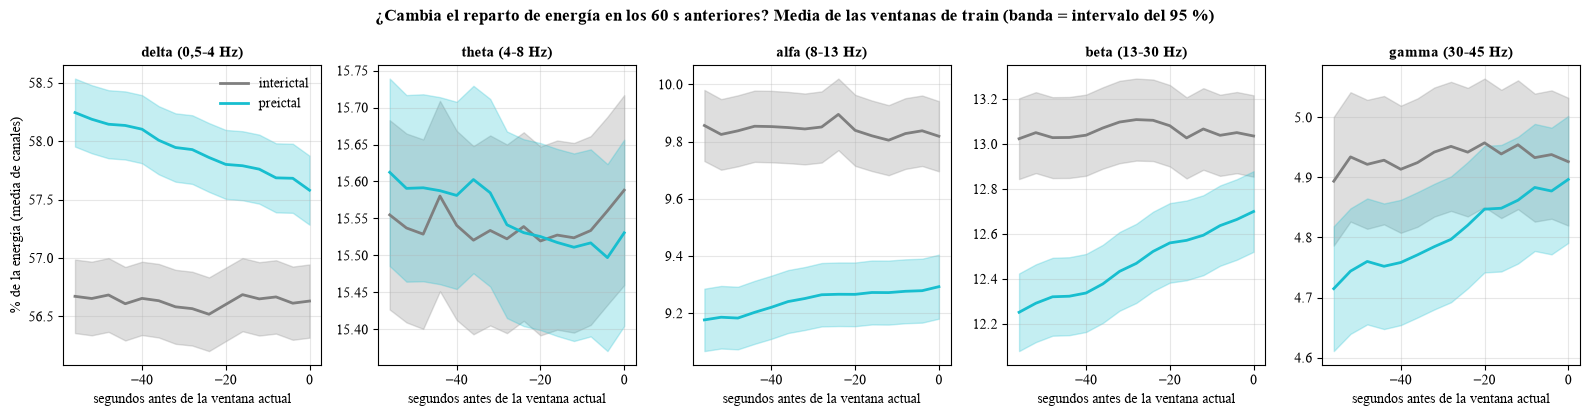

In [9]:
X_contexto = {}
for contexto in CONTEXTOS:
    k = ventanas_por_contexto(contexto, VENTANA_S)
    cubo = cubo_contexto(filas, k, MUESTRAS, claves_guardadas, valores)
    X_contexto[contexto] = cubo[:, -1, :] if k == 1 else resumir_contexto(cubo)
nombres_por_contexto = {c: NOMBRES if ventanas_por_contexto(c, VENTANA_S) == 1 else nombres_contexto(NOMBRES) for c in CONTEXTOS}
display(con_separadores(pd.DataFrame({'ventanas de 4 s': [ventanas_por_contexto(c, VENTANA_S) for c in CONTEXTOS],
                                      'números por ventana': [X_contexto[c].shape[1] for c in CONTEXTOS]},
                                     index=pd.Index([f'{c} s' for c in CONTEXTOS], name='contexto')), decimales=0))

# Figura: cómo evoluciona el reparto de energía en el último contexto, en ⏳ y en 💤 (🔵 train)
cubo_max = cubo_contexto(filas, K_MAX, MUESTRAS, claves_guardadas, valores)               # ventanas × K_MAX × 110
por_banda = np.nanmean(10 ** cubo_max.reshape(len(filas), K_MAX, len(CANALES_TCP), len(BANDAS)), axis=2) * 100   # % por banda
segundos = -VENTANA_S * np.arange(K_MAX - 1, -1, -1)                                       # inicio de cada ventana respecto a la actual
en_entrena = filas.en_entrenamiento.to_numpy(dtype=bool)
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(BANDAS), figsize=(16, 4.2), sharex=True)
    for b, (ax, banda) in enumerate(zip(axes, BANDAS)):
        for clase, etiqueta in [('interictal', 0), ('preictal', 1)]:
            datos = por_banda[en_entrena & (y == etiqueta), :, b]
            media = np.nanmean(datos, axis=0)
            error = 1.96 * np.nanstd(datos, axis=0) / np.sqrt(np.sum(~np.isnan(datos), axis=0))
            ax.plot(segundos, media, color=COLORES_PERIODO[clase], lw=2, label=clase)
            ax.fill_between(segundos, media - error, media + error, color=COLORES_PERIODO[clase], alpha=0.25)
        ax.set_title(f'{banda} ({numero_legible(BANDAS_HZ[banda][0])}-{numero_legible(BANDAS_HZ[banda][1])} Hz)', fontsize=11, fontweight='bold')
        ax.set_xlabel('segundos antes de la ventana actual')
        ax.grid(alpha=0.3)
    axes[0].set_ylabel('% de la energía (media de canales)')
    axes[0].legend(frameon=False)
    fig.suptitle(f'¿Cambia el reparto de energía en los {max(CONTEXTOS)} s anteriores? Media de las ventanas de train (banda = intervalo del 95 %)',
                 fontsize=12, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'evolucion_contexto.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Un panel por banda. El eje horizontal son los segundos antes de la ventana actual (0 = la actual); el vertical, qué % de la energía cae en esa banda (media de los 22 canales). Gris = 💤 interictal, azul claro = ⏳ preictal; la banda sombreada es el intervalo del 95 % de la media.

✅ **Qué deberías ver:** si las curvas ⏳ y 💤 van **separadas** pero **planas**, el contexto aporta poco (lo de antes es igual que lo de ahora). Si la ⏳ **sube o baja hacia el 0** (tendencia), el contexto puede ayudar: es justo lo que miden la *variación* y el *cambio*.

## 6. Cada paciente frente a sí mismo

> 🎯 **Qué hacemos:** preparar la segunda palanca: a cada característica de cada paciente se le resta **su mediana** (su valor habitual) y se divide por su rango intercuartílico (lo que suele variar). Se hace de **dos formas**, que se comparan en §7 y §9.
>
> 🤔 **Por qué:** en F03.02, la AUC **por paciente** de la logística (≈ 0,58) salió más alta que la global (≈ 0,51): dentro de cada paciente ordena algo mejor, pero cada persona está en su propio "nivel" y un umbral común falla.

![Cada paciente frente a sí mismo](img/normalizacion_paciente.png)

👀 **Qué enseña.** A la izquierda, dos pacientes con niveles distintos: las ⏳ (rojo) del paciente B quedan por debajo de las 💤 (blanco) del A, y ningún umbral común las separa. A la derecha, restada la mediana de cada uno, las ⏳ de los dos quedan a la derecha y un mismo umbral sirve. Abajo, las dos formas de calcular esa mediana.

**Las dos formas, y por qué hacen falta las dos:**

| Normalización | Con qué ventanas se calcula la mediana de cada paciente | Ventaja | Pega |
|---|---|---|---|
| `por_paciente` | **Todas** sus ventanas, sin mirar etiquetas | No usa ninguna etiqueta | Sus ⏳ también entran en la mediana, y en 🔵 train hay mitad y mitad pero en 🟡 dev muchas menos ⏳: la mediana se mueve distinto en cada partición y eso podría ayudar "de rebote" |
| `por_paciente_calibrado` | **Solo** sus 💤 interictales, y ninguna ventana se calibra consigo misma (las 💤 se parten en dos mitades seguidas y cada mitad se calibra con la otra) | Es como una app que graba unos minutos **tranquilos** del paciente: las ⏳ no influyen | Usa saber qué ventanas son tranquilas (en una app, el paciente o su médico lo indicaría al calibrar) |

> 🧪 **La prueba de robustez.** Si la mejora de `por_paciente` es de verdad, `por_paciente_calibrado` debería dar una nota parecida. Si se cae al azar, la mejora venía de cómo se calcula la mediana y no se puede contar como predicción. Se decide en §9.

In [10]:
es_tranquila = (y == 0)                       # las 💤 interictales: las únicas que sirven para la calibración tranquila
def preparar(X, normalizacion):
    if normalizacion == 'por_paciente':
        return normalizar_por_paciente(X, pacientes)
    if normalizacion == 'por_paciente_calibrado':
        return normalizar_con_calibracion(X, pacientes, es_tranquila)
    return X

## 7. Medir en dev: cada contexto, con y sin normalización por paciente

> 🎯 **Qué hacemos:** entrenar los dos modelos de F03.02 (mismos hiperparámetros y variante) con cada contexto y cada normalización, y medirlos en 🟡 dev con las mismas métricas.
>
> 🤔 **Por qué:** es el estudio en sí: cuánto contexto hace falta y si comparar a cada paciente consigo mismo ayuda.

![Las cuatro combinaciones que se prueban](img/cuatro_combinaciones.png)

👀 **Qué enseña.** El diseño del estudio en una tabla de 2 × 2: con o sin contexto (columnas) y con o sin comparar a cada paciente consigo mismo (filas). Cada casilla lleva su equivalente con la tensión arterial. La hipótesis es que solo la casilla roja, **las dos cosas juntas**, anuncia la crisis. Aquí se prueban además varios contextos (8, 16, 32 y 60 s) y dos formas de normalizar, así que cada casilla se convierte en varias filas de la tabla de abajo.

In [11]:
filas_res, puntuaciones = {}, {}
inicio = time.time()
for nombre, (variante, hp) in MODELOS.items():
    for normalizacion in NORMALIZACIONES:
        for contexto in CONTEXTOS:
            X = preparar(X_contexto[contexto], normalizacion)
            p = np.full(len(filas), np.nan)
            for _, entrena, valida in rondas:
                modelo = entrenar(nombre, hp, X[entrena], y[entrena], pacientes[entrena], variante, SEMILLA)
                p[valida] = puntuar(modelo, X[valida])
            puntuaciones[(nombre, normalizacion, contexto)] = p
            auc, inferior, superior = auroc_con_intervalo(y[validar], p[validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
            pp = auroc_por_paciente(y[validar], p[validar], pacientes[validar])
            filas_res[(NOMBRES_MODELO[nombre], normalizacion, contexto)] = {
                'AUC-ROC': auc, 'IC 95 % (por paciente)': f'{decimal(inferior)} – {decimal(superior)}',
                f'sensibilidad con especificidad {numero_legible(100 * ESPECIFICIDAD)} %': sensibilidad_con_especificidad(y[validar], p[validar], ESPECIFICIDAD)[0],
                'AUC por paciente (mediana)': float(pp.auroc.median()) if len(pp) else np.nan,
                '_inferior': inferior, '_superior': superior}
resultados = pd.DataFrame(filas_res).T.infer_objects()
resultados.index.names = ['modelo', 'normalización', 'contexto (s)']
resultados = resultados.sort_index()   # ordenado por modelo, normalización y contexto (de menos a más segundos)
display(con_separadores(resultados.drop(columns=['_inferior', '_superior']), decimales=3))
print(f'{len(resultados)} entrenamientos en {numero_legible(round((time.time() - inicio) / 60, 1))} min')

30 entrenamientos en 5,5 min


👀 **Cómo leer la tabla.** Una fila por modelo, normalización y contexto. La fila de **4 s sin normalización** es la línea base de F03.02 medida con estas ventanas (puede salir un poco distinta del 0,54 porque el subconjunto es algo menor). Las columnas son las de F03.02: AUC con su intervalo, sensibilidad con especificidad fija y AUC por paciente.

✅ **Qué deberías ver:** si el contexto ayuda, la AUC sube al bajar por cada bloque (más segundos). Si la normalización por paciente ayuda, el bloque *por_paciente* queda por encima de *ninguna*. La figura de abajo lo enseña de un vistazo.

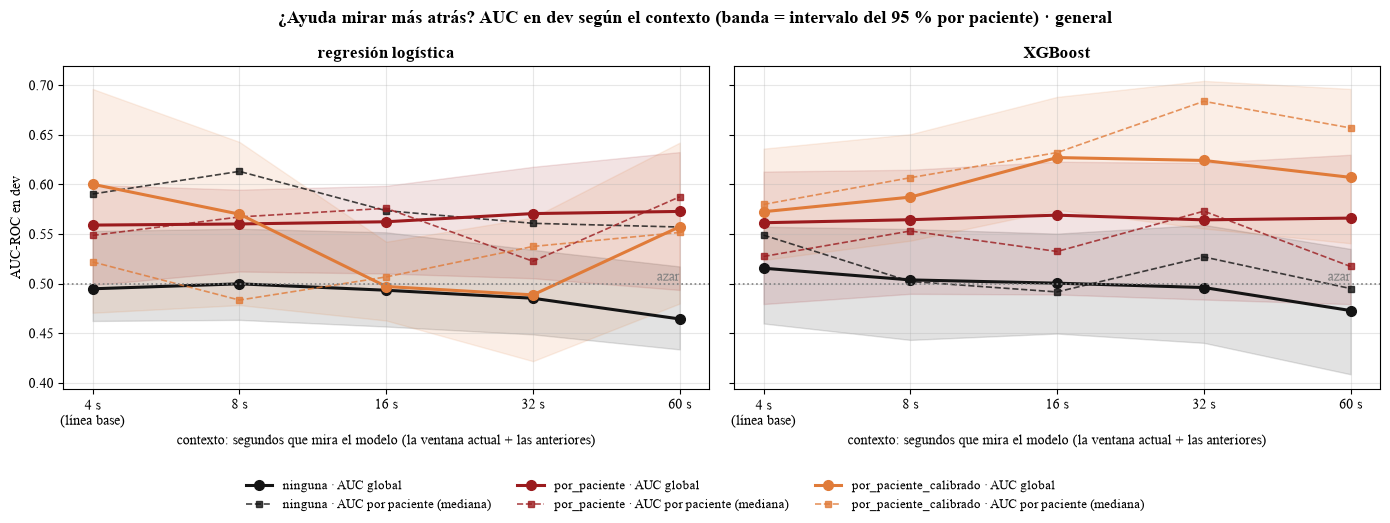

In [12]:
# Figura principal: AUC en dev según el contexto, para cada modelo y normalización
COLOR_NORMALIZACION = {'ninguna': COLORES_ESQUEMA['negro'], 'por_paciente': COLORES_ESQUEMA['rojo'], 'por_paciente_calibrado': '#e07b39'}
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(MODELOS), figsize=(14, 5.2), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, nombre in zip(axes, MODELOS):
        for normalizacion in NORMALIZACIONES:
            t = resultados.loc[(NOMBRES_MODELO[nombre], normalizacion)]
            x = np.arange(len(CONTEXTOS))
            color = COLOR_NORMALIZACION[normalizacion]
            ax.plot(x, t['AUC-ROC'], 'o-', color=color, lw=2.2, ms=7, label=f'{normalizacion} · AUC global')
            ax.fill_between(x, t['_inferior'], t['_superior'], color=color, alpha=0.12)
            ax.plot(x, t['AUC por paciente (mediana)'], 's--', color=color, lw=1.2, ms=5, alpha=0.8, label=f'{normalizacion} · AUC por paciente (mediana)')
        ax.axhline(0.5, color='gray', ls=':', lw=1.2)
        ax.text(len(CONTEXTOS) - 1, 0.5, ' azar', color='gray', va='bottom', ha='right', fontsize=10)
        ax.set_xticks(range(len(CONTEXTOS)), [f'{c} s' + ('\n(línea base)' if c == min(CONTEXTOS) else '') for c in CONTEXTOS])
        ax.set_xlabel('contexto: segundos que mira el modelo (la ventana actual + las anteriores)')
        ax.set_title(NOMBRES_MODELO[nombre], fontsize=12, fontweight='bold')
        ax.grid(alpha=0.3)
    axes[0].set_ylabel('AUC-ROC en dev')
    fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=9.5, frameon=False)
    fig.suptitle(f'¿Ayuda mirar más atrás? AUC en dev según el contexto (banda = intervalo del 95 % por paciente) · {CONJUNTO}',
                 fontsize=13, fontweight='bold')
    fig.tight_layout(rect=(0, 0.11, 1, 1))
    fig.savefig(RUTA_FIGURAS / 'auc_segun_contexto.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Un panel por modelo. Eje horizontal: cuántos segundos mira el modelo (4 s = la línea base de F03.02). Negro = sin normalizar; rojo = cada paciente frente a la mediana de todas sus ventanas; naranja = frente a la mediana de solo sus 💤 (calibración tranquila). Línea continua con círculos = AUC global (la banda es su intervalo del 95 %); discontinua con cuadrados = la mediana de la AUC **dentro** de cada paciente. La línea de puntos es el azar.

✅ **Qué deberías ver:** si alguna línea **sube** con el contexto y su banda se separa del 0,5, mirar atrás ayuda. Lo más convincente es una subida **ordenada** (cada contexto algo mejor que el anterior), no un pico suelto. Y si la naranja va cerca de la roja, la mejora de normalizar por paciente es robusta. Si todo se queda plano en torno a 0,5, ni el contexto ni la normalización bastan con modelos clásicos.

## 8. Por grupo de crisis: ¿cuánto contexto le va a cada uno?

> 🎯 **Qué hacemos:** con la normalización y el modelo que mejor salen en §7, repetir la AUC **por grupo de inicio** (⏳ de ese grupo frente a todas las 💤) para cada contexto.
>
> 🤔 **Por qué:** la idea de partida era que cada tipo de crisis puede necesitar un contexto distinto: corto en las ausencias (aparecen de golpe) y más largo en focales y generalizadas (podrían prepararse más despacio). Aquí se ve con datos.

**AUC en dev por grupo y contexto** (XGBoost, normalización por_paciente_calibrado)

,4 s,8 s,16 s,32 s,60 s,mejor contexto,pacientes con ⏳
grupo de inicio,,,,,,,
♦️ focal,"0,574","0,580","0,624","0,610","0,582",16 s,20
🔷 generalizada,"0,584","0,622","0,650","0,675","0,683",60 s,16
🔹 ausencia,"0,446","0,456","0,508","0,518","0,529",60 s,3


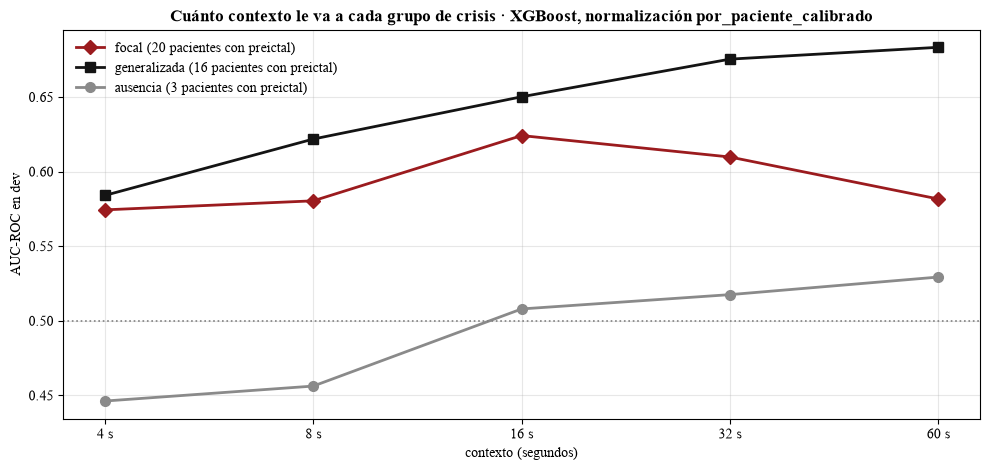

In [13]:
mejor = resultados['AUC-ROC'].idxmax()                            # (modelo, normalización, contexto)
nombre_mejor = next(n for n, bonito in NOMBRES_MODELO.items() if bonito == mejor[0])
grupos = [g for g in ['focal', 'generalizada', 'ausencia'] if g in set(filas.grupo[validar & (y == 1)].dropna())]
filas_grupo = {}
for grupo in grupos:
    mascara = validar & ((y == 0) | (filas.grupo.to_numpy() == grupo))
    for contexto in CONTEXTOS:
        p = puntuaciones[(nombre_mejor, mejor[1], contexto)]
        auc, inferior, superior = auroc_con_intervalo(y[mascara], p[mascara], pacientes[mascara], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        filas_grupo[(con_icono(grupo), contexto)] = {'AUC-ROC': auc, 'IC 95 %': f'{decimal(inferior)} – {decimal(superior)}',
                                                     'pacientes con ⏳': len(set(pacientes[mascara & (y == 1)]))}
por_grupo = pd.DataFrame(filas_grupo).T.infer_objects()
por_grupo.index.names = ['grupo de inicio', 'contexto (s)']
if len(por_grupo):
    tabla_grupo = por_grupo['AUC-ROC'].unstack('contexto (s)')
    tabla_grupo.columns = [f'{c} s' for c in tabla_grupo.columns]
    tabla_grupo['mejor contexto'] = [f'{CONTEXTOS[int(np.nanargmax(v))]} s' for v in tabla_grupo.to_numpy(dtype=float)]
    tabla_grupo['pacientes con ⏳'] = por_grupo.groupby(level=0, sort=False)['pacientes con ⏳'].first()
    display(Markdown(f'**AUC en dev por grupo y contexto** ({mejor[0]}, normalización {mejor[1]})'))
    display(con_separadores(tabla_grupo, decimales=3))

    marcadores = {'♦️ focal': 'D', '🔷 generalizada': 's', '🔹 ausencia': 'o'}
    with plt.rc_context(ESTILO_TIMES):
        fig, ax = plt.subplots(figsize=(10, 4.8))
        for (grupo, t), color in zip(por_grupo.groupby(level=0, sort=False), [COLORES_ESQUEMA['rojo'], COLORES_ESQUEMA['negro'], COLORES_ESQUEMA['gris']]):
            nombre_limpio = grupo.split(' ', 1)[-1]
            ax.plot(range(len(CONTEXTOS)), t['AUC-ROC'].to_numpy(), marker=marcadores.get(grupo, 'o'), color=color, lw=2, ms=7,
                    label=f'{nombre_limpio} ({int(t["pacientes con ⏳"].iloc[0])} pacientes con preictal)')
        ax.axhline(0.5, color='gray', ls=':', lw=1.2)
        ax.set_xticks(range(len(CONTEXTOS)), [f'{c} s' for c in CONTEXTOS])
        ax.set_xlabel('contexto (segundos)')
        ax.set_ylabel('AUC-ROC en dev')
        ax.set_title(f'Cuánto contexto le va a cada grupo de crisis · {mejor[0]}, normalización {mejor[1]}', fontsize=12, fontweight='bold')
        ax.grid(alpha=0.3)
        ax.legend(frameon=False)
        fig.tight_layout()
        fig.savefig(RUTA_FIGURAS / 'auc_por_grupo_y_contexto.png', dpi=150, bbox_inches='tight')
        plt.show()
else:
    print('🟡 Las ventanas de validación no traen el grupo de inicio: no se puede separar por grupo.')

👀 **Cómo leer la tabla y la figura.** Una fila (y una línea) por grupo de inicio; una columna por contexto. La columna *mejor contexto* dice con cuál sale la AUC más alta para ese grupo.

✅ **Qué deberías ver:** si la idea de partida se cumple, las 🔹 ausencias tendrán su mejor nota con contextos cortos y los ♦️ focales / 🔷 generalizados con contextos más largos. **Cuidado** con los grupos de pocos pacientes: un salto de una columna a otra puede ser ruido. La cifra seria de las ausencias es la del conjunto `grupo_ausencia` (validación cruzada por paciente).

## 9. Decidir: ¿qué hereda la red?

> 🎯 **Qué hacemos:** comparar la mejor combinación con la línea base (4 s, sin normalizar, mismo modelo) con una **diferencia emparejada**: los dos se miden con las mismas ventanas y los mismos sorteos de pacientes.
>
> 🤔 **Por qué:** dos intervalos que se solapan no dicen si una mejora es real. La diferencia emparejada sí: si su intervalo no incluye el 0, la mejora no es casualidad. Y aunque sea real, si es muy pequeña (menos de `MEJORA_MINIMA`), no compensa complicar la red.

In [14]:
base = (nombre_mejor, 'ninguna', min(CONTEXTOS))
diferencia, dif_inf, dif_sup = diferencia_auroc_con_intervalo(y[validar], puntuaciones[(nombre_mejor, mejor[1], mejor[2])][validar],
                                                              puntuaciones[base][validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
# Lo mismo separando las dos palancas: solo contexto (sin normalizar) y solo normalización (4 s)
mejor_ctx = resultados.loc[(mejor[0], 'ninguna'), 'AUC-ROC'].idxmax()
solo_contexto = diferencia_auroc_con_intervalo(y[validar], puntuaciones[(nombre_mejor, 'ninguna', mejor_ctx)][validar],
                                               puntuaciones[base][validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
solo_paciente = diferencia_auroc_con_intervalo(y[validar], puntuaciones[(nombre_mejor, 'por_paciente', min(CONTEXTOS))][validar],
                                               puntuaciones[base][validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
comparacion = pd.DataFrame({
    'qué se compara con la línea base (4 s, sin normalizar)': [f'solo contexto ({mejor_ctx} s)', 'solo normalización por paciente (4 s)',
                                                                f'la mejor combinación ({mejor[2]} s, {mejor[1]})'],
    'diferencia de AUC': [con_signo(d) for d in [solo_contexto[0], solo_paciente[0], diferencia]],
    'IC 95 % de la diferencia': [f'{decimal(a, 3)} – {decimal(b, 3)}' for _, a, b in [solo_contexto, solo_paciente, (diferencia, dif_inf, dif_sup)]],
    '¿real? (el IC no incluye el 0)': ['sí' if a > 0 or b < 0 else 'no' for _, a, b in [solo_contexto, solo_paciente, (diferencia, dif_inf, dif_sup)]],
}).set_index('qué se compara con la línea base (4 s, sin normalizar)')

mejora_clara = dif_inf > 0 and diferencia >= MEJORA_MINIMA
auc_mejor, inf_mejor, sup_mejor = resultados.loc[mejor, ['AUC-ROC', '_inferior', '_superior']]

# Prueba de robustez: la misma combinación (modelo y contexto), pero con la calibración tranquila (solo 💤)
calibrada = (nombre_mejor, 'por_paciente_calibrado', mejor[2])
robustez = diferencia_auroc_con_intervalo(y[validar], puntuaciones[calibrada][validar], puntuaciones[base][validar], pacientes[validar],
                                          n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
auc_calibrada = float(resultados.loc[(mejor[0], 'por_paciente_calibrado', mejor[2]), 'AUC-ROC'])
if mejor[1] == 'ninguna':
    robusto, texto_robustez = True, 'La mejor combinación no normaliza por paciente: la prueba de robustez no hace falta.'
else:
    robusto = robustez[1] > 0 and auc_calibrada >= auc_mejor - MEJORA_MINIMA
    texto_robustez = (f'Con la calibración tranquila (solo 💤), la misma combinación da AUC <b>{decimal(auc_calibrada)}</b> '
                      f'({con_signo(robustez[0])} sobre la línea base; IC {decimal(robustez[1], 3)} – {decimal(robustez[2], 3)}). '
                      + ('<b>✅ Se mantiene: la mejora es robusta</b>, no viene de cómo se calcula la mediana.' if robusto else
                         ('🟡 Sigue mejorando a la línea base, pero bastante menos: parte de la mejora venía de la forma de calibrar.' if robustez[1] > 0 else
                          '🔴 <b>Se cae</b>: con la calibración tranquila no hay mejora segura. La mejora de antes dependía de cómo se calcula la mediana.')))
comparacion.loc[f'robustez: la misma, con calibración tranquila ({mejor[2]} s, solo 💤)'] = [
    con_signo(robustez[0]), f'{decimal(robustez[1], 3)} – {decimal(robustez[2], 3)}', 'sí' if robustez[1] > 0 or robustez[2] < 0 else 'no']
if mejora_clara:
    decision = (f'La red recibirá {mejor[2]} s de contexto' + (' y cada paciente normalizado frente a sí mismo' if mejor[1] != 'ninguna' else '')
                + ('' if robusto else ' (🟡 robustez por confirmar)'),
                f'<b>{mejor[0]}</b> con <b>{mejor[2]} s</b> de contexto y normalización <b>{mejor[1]}</b> → AUC {con_intervalo(auc_mejor, inf_mejor, sup_mejor)}. '
                f'Mejora a la línea base en <b>{con_signo(diferencia)}</b> (IC {decimal(dif_inf, 3)} – {decimal(dif_sup, 3)}): es real y compensa.')
    contexto_red, normalizacion_red = int(mejor[2]), (mejor[1] if robusto or mejor[1] == 'ninguna' else 'por_paciente_calibrado')
else:
    decision = ('Ninguna palanca mejora de forma clara',
                f'La mejor combinación ({mejor[0]}, {mejor[2]} s, {mejor[1]}) da AUC {con_intervalo(auc_mejor, inf_mejor, sup_mejor)}, '
                f'{con_signo(diferencia)} sobre la línea base (IC {decimal(dif_inf, 3)} – {decimal(dif_sup, 3)}): '
                + ('no es una mejora segura.' if dif_inf <= 0 else f'real, pero menor que {decimal(MEJORA_MINIMA)}.')
                + ' La red empezará con la ventana sola y probará el contexto como experimento.')
    contexto_red, normalizacion_red = int(min(CONTEXTOS)), 'ninguna'
mostrar_destacado(f'Decisión para la red (F03.04) · {decision[0]}', decision[1], texto_robustez, con_separadores(comparacion, decimales=3))

,diferencia de AUC,IC 95 % de la diferencia,¿real? (el IC no incluye el 0)
"qué se compara con la línea base (4 s, sin normalizar)",,,
solo contexto (4 s),"+0,000","0,000 – 0,000",no
solo normalización por paciente (4 s),"+0,046","-0,028 – 0,092",no
"la mejor combinación (16 s, por_paciente_calibrado)","+0,112","0,038 – 0,199",sí
"robustez: la misma, con calibración tranquila (16 s, solo 💤)","+0,112","0,038 – 0,199",sí


👀 **Cómo leer el recuadro.** Cuatro comparaciones con la línea base, siempre con el mismo modelo y las mismas ventanas: solo el contexto, solo la normalización por paciente, las dos juntas (la mejor combinación) y la **prueba de robustez** (la mejor combinación con la calibración tranquila). El segundo párrafo dice si la mejora aguanta esa prueba; si no aguanta, la red usará la calibración tranquila, que es la honesta. La **diferencia de AUC** es cuánto mejora (o empeora) y su **intervalo** dice si es real: si no incluye el 0, sí. Arriba, la decisión que hereda la red.

✅ **Qué deberías ver:** cuál de las dos palancas aporta más. Si ninguna mejora de forma clara, también es una conclusión valiosa para la memoria: con modelos clásicos y potencia por bandas, ni mirar un minuto atrás ni calibrar por paciente bastan para anunciar la crisis.

## 10. Control de sesión: ¿predice la crisis o reconoce la grabación?

> 🎯 **Qué hacemos:** repetir la nota en 🟡 dev quitando la pista tramposa más peligrosa, la de la **sesión de grabación**. Se comparan las ⏳ solo con 💤 de **las mismas sesiones** (y, aún más estricto, de los mismos ficheros) del mismo paciente.
>
> 🤔 **Por qué:** F02.05 encontró que el **tipo de fichero / sesión** separa mucho las clases (H5): las ⏳ salen de las grabaciones con crisis y muchas 💤 de **otras** grabaciones del mismo paciente (otro día, otros electrodos). Al calibrar con las 💤 y promediar 60 s, cualquier diferencia **entre grabaciones** se ve todavía mejor. El modelo podría estar aprendiendo *"esta grabación es distinta de lo normal"* y no *"se acerca una crisis"*.

![El control de sesión](img/control_sesion_esquema.png)

👀 **Qué enseña.** Un paciente con tres grabaciones de días distintos; solo la del lunes tiene una crisis. Si el modelo comparase las ⏳ del lunes con 💤 del martes y del jueves, podría acertar solo porque **son grabaciones distintas** (otros electrodos, otro estado del paciente), sin saber nada de crisis. El control de *misma sesión* usa solo 💤 del lunes: así esa pista desaparece.

**Los tres grupos de 💤 que se comparan** (las ⏳ son siempre las mismas):

| Control | Qué 💤 se usan | Qué quita |
|---|---|---|
| todas las 💤 | todas las de 🟡 dev (lo de §7) | nada |
| misma sesión | solo las de las **sesiones** (`_s00X`) en las que ese paciente tiene alguna ⏳ | la diferencia entre días de grabación |
| mismo fichero | solo las de los **ficheros** (`_t00X`) en los que ese paciente tiene alguna ⏳ | también la diferencia entre ficheros. Ojo: muchas de estas 💤 son de **después** de la crisis (F02.05), así que es un control muy duro |

Se miden la línea base (4 s, sin normalizar) y la mejor combinación, con los **mismos** modelos de §7 (no se reentrena nada). Si la mejora es predicción de verdad, debe **mantenerse** en los controles.

,pacientes con las dos clases,⏳ preictal,💤 interictal,AUC línea base,IC línea base,AUC mejor,IC mejor,mejora (mejor − línea base),IC de la mejora
qué 💤 se usan,,,,,,,,,
todas las 💤,30,8.193,42.975,"0,52","0,46 – 0,56","0,63","0,57 – 0,69","+0,112","0,038 – 0,199"
misma sesión,26,8.193,8.640,"0,52","0,48 – 0,55","0,62","0,57 – 0,70","+0,099","0,041 – 0,191"
mismo fichero,20,8.193,1.386,"0,52","0,43 – 0,58","0,69","0,62 – 0,76","+0,170","0,071 – 0,293"


🟡 **Ojo con *mismo fichero*:** sube a AUC 0,69, por encima de §7. En ese control casi todas las 💤 son de **después** de la crisis (F02.05), así que el modelo podría estar distinguiendo también "antes" de "después" de una crisis. No invalida el resultado (el control importante es el de la sesión), pero hay que vigilarlo con la red y contarlo en la memoria.

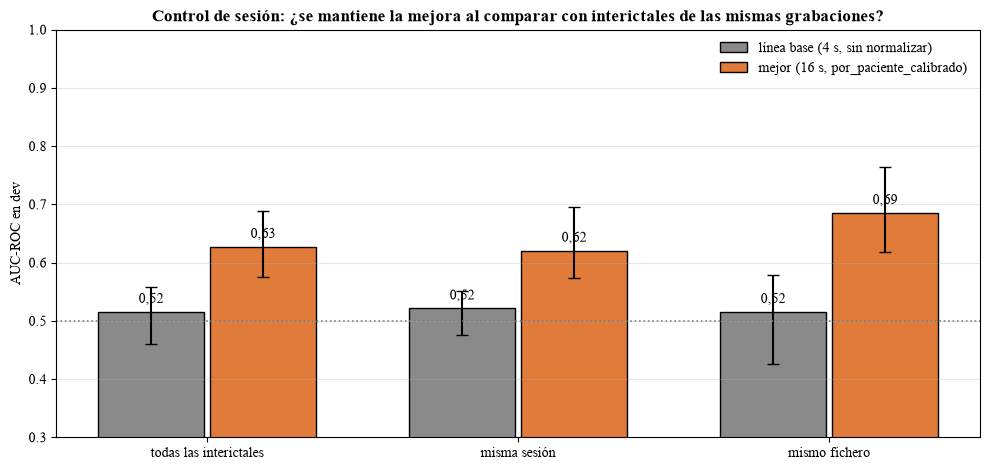

In [15]:
sesion = filas.file.astype(str).str.extract(r'^(.*?_s\d+)')[0].fillna(filas.file.astype(str)).to_numpy()
fichero = filas.file.astype(str).to_numpy()

def mascara_control(grupo):
    # ⏳ de validación + solo las 💤 de validación de los grupos (sesión o fichero) en los que su paciente tiene alguna ⏳
    con_preictal = set(zip(pacientes[validar & (y == 1)], grupo[validar & (y == 1)]))
    mismo = np.fromiter(((p, g) in con_preictal for p, g in zip(pacientes, grupo)), dtype=bool, count=len(filas))
    return validar & ((y == 1) | ((y == 0) & mismo))

controles_dev = {'todas las 💤': validar, 'misma sesión': mascara_control(sesion), 'mismo fichero': mascara_control(fichero)}
clave_mejor = (nombre_mejor, mejor[1], mejor[2])
filas_control, notas_control = {}, {}
for nombre_control, m in controles_dev.items():
    if (y[m] == 0).sum() == 0 or (y[m] == 1).sum() == 0:
        continue
    pac_dos = {p for p in set(pacientes[m]) if len(set(y[m & (pacientes == p)])) == 2}
    fila = {'pacientes con las dos clases': len(pac_dos), '⏳ preictal': int((y[m] == 1).sum()), '💤 interictal': int((y[m] == 0).sum())}
    for etiqueta, clave_m in [('línea base', base), ('mejor', clave_mejor)]:
        a, i_, s_ = auroc_con_intervalo(y[m], puntuaciones[clave_m][m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        fila[f'AUC {etiqueta}'] = a
        fila[f'IC {etiqueta}'] = f'{decimal(i_)} – {decimal(s_)}'
        notas_control[(nombre_control, etiqueta)] = (a, i_, s_)
    d = diferencia_auroc_con_intervalo(y[m], puntuaciones[clave_mejor][m], puntuaciones[base][m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    fila['mejora (mejor − línea base)'] = con_signo(d[0])
    fila['IC de la mejora'] = f'{decimal(d[1], 3)} – {decimal(d[2], 3)}'
    notas_control[(nombre_control, 'diferencia')] = d
    filas_control[nombre_control] = fila
control_sesion = pd.DataFrame(filas_control).T.infer_objects()
control_sesion.index.name = 'qué 💤 se usan'

# Veredicto con el control de misma sesión (el más importante): ¿se mantiene la mejora?
if 'misma sesión' in filas_control:
    auc_ses, inf_ses, _ = notas_control[('misma sesión', 'mejor')]
    dif_ses = notas_control[('misma sesión', 'diferencia')]
    if dif_ses[1] > 0 and auc_ses >= auc_mejor - 0.05:
        veredicto_sesion = ('✅ Se mantiene: predice la crisis, no la grabación',
                            f'Con solo 💤 de las mismas sesiones, la mejor combinación da <b>AUC {decimal(auc_ses)}</b> (en §7: {decimal(auc_mejor)}) '
                            f'y sigue mejorando a la línea base en <b>{con_signo(dif_ses[0])}</b> (IC {decimal(dif_ses[1], 3)} – {decimal(dif_ses[2], 3)}).')
    elif dif_ses[1] > 0:
        veredicto_sesion = ('🟡 Se mantiene en parte',
                            f'Con solo 💤 de las mismas sesiones baja a <b>AUC {decimal(auc_ses)}</b> (en §7: {decimal(auc_mejor)}), aunque sigue mejorando a la '
                            f'línea base ({con_signo(dif_ses[0])}; IC {decimal(dif_ses[1], 3)} – {decimal(dif_ses[2], 3)}). Parte de la mejora venía de reconocer la grabación.')
    else:
        veredicto_sesion = ('🔴 Se cae: reconocía la grabación',
                            f'Con solo 💤 de las mismas sesiones, la mejora desaparece (AUC {decimal(auc_ses)}; {con_signo(dif_ses[0])}, '
                            f'IC {decimal(dif_ses[1], 3)} – {decimal(dif_ses[2], 3)}). La red tendrá que entrenarse y medirse con este control desde el principio.')
else:
    veredicto_sesion = ('🟡 Sin control de sesión', 'En dev no hay 💤 de las mismas sesiones que las ⏳: no se puede hacer este control.')
mostrar_destacado(f'Control de sesión · {veredicto_sesion[0]}', veredicto_sesion[1], con_separadores(control_sesion, decimales=3))
if 'mismo fichero' in filas_control and notas_control[('mismo fichero', 'mejor')][0] > auc_mejor + 0.05:
    display(Markdown(f'🟡 **Ojo con *mismo fichero*:** sube a AUC {decimal(notas_control[("mismo fichero", "mejor")][0])}, por encima de §7. '
                     'En ese control casi todas las 💤 son de **después** de la crisis (F02.05), así que el modelo podría estar distinguiendo también '
                     '"antes" de "después" de una crisis. No invalida el resultado (el control importante es el de la sesión), pero hay que vigilarlo '
                     'con la red y contarlo en la memoria.'))

# Figura: AUC de la línea base y de la mejor combinación en cada control
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    nombres_c = list(filas_control)
    for k, (etiqueta, color) in enumerate([('línea base', COLORES_ESQUEMA['gris']), ('mejor', '#e07b39')]):
        valores_c = np.array([notas_control[(c, etiqueta)] for c in nombres_c])
        x = np.arange(len(nombres_c)) + (k - 0.5) * 0.36
        ax.bar(x, valores_c[:, 0], width=0.34, color=color, edgecolor='black',
               label='línea base (4 s, sin normalizar)' if etiqueta == 'línea base' else f'mejor ({mejor[2]} s, {mejor[1]})')
        ax.errorbar(x, valores_c[:, 0], yerr=[valores_c[:, 0] - valores_c[:, 1], valores_c[:, 2] - valores_c[:, 0]], fmt='none', ecolor='black', capsize=4)
        for xi, v in zip(x, valores_c[:, 0]):
            ax.text(xi, v + 0.01, decimal(v), ha='center', va='bottom', fontsize=10)
    ax.axhline(0.5, color='gray', ls=':', lw=1.2)
    ax.set_xticks(range(len(nombres_c)), [c.replace('💤', 'interictales') for c in nombres_c])
    ax.set_ylabel('AUC-ROC en dev')
    ax.set_ylim(0.3, 1)
    ax.set_title('Control de sesión: ¿se mantiene la mejora al comparar con interictales de las mismas grabaciones?', fontsize=12, fontweight='bold')
    ax.legend(frameon=False, loc='upper right')
    ax.grid(axis='y', alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'control_sesion.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer el recuadro y la figura.** Una fila (y una pareja de barras) por control. Para cada uno: cuántos pacientes tienen las dos clases, cuántas ventanas de cada clase quedan, la AUC de la línea base y de la mejor combinación con sus intervalos, y la **mejora emparejada** (mejor − línea base) con el suyo. El recuadro da el veredicto con el control de **misma sesión**, el que importa:

- ✅ la mejor combinación sigue cerca de su nota de §7 (a menos de 0,05) y sigue mejorando a la línea base: **predice la crisis**;
- 🟡 sigue mejorando, pero baja bastante: parte de la mejora era reconocer la grabación;
- 🔴 la mejora desaparece: el modelo reconocía la grabación.

✅ **Qué deberías ver:** la barra naranja por encima de la gris también en *misma sesión*. En *mismo fichero* es normal que todo baje (control muy duro: muchas 💤 son de después de la crisis y quedan pocos pacientes).

## 11. El resultado → tablas y `configuracion.json`

In [16]:
resultados.drop(columns=['_inferior', '_superior']).assign(ic_inferior=resultados._inferior, ic_superior=resultados._superior).reset_index().to_csv(
    RUTA_RESULTADOS / 'resultados_contexto.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'resultados_contexto.csv', 'una fila por modelo, normalización y contexto: AUC en 🟡 dev con su intervalo, '
                'sensibilidad con especificidad fija y AUC por paciente')
if len(por_grupo):
    por_grupo.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_grupo_y_contexto.csv', index=False)
    mostrar_fichero(RUTA_RESULTADOS / 'auc_por_grupo_y_contexto.csv', f'una fila por grupo de inicio y contexto: AUC de {mejor[0]} ({mejor[1]}) con las ⏳ de ese grupo frente a todas las 💤')
comparacion.reset_index().to_csv(RUTA_RESULTADOS / 'decision.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'decision.csv', 'la comparación emparejada con la línea base (solo contexto, solo normalización y las dos juntas)')
control_sesion.reset_index().to_csv(RUTA_RESULTADOS / 'control_sesion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'control_sesion.csv', 'el control de sesión (§10): AUC de la línea base y de la mejor combinación con todas las 💤, con las de la misma sesión y con las del mismo fichero')

puntos = filas.loc[validar, ['id_ventana', 'split', 'patient', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
puntos['puntuacion_linea_base_4s'] = puntuaciones[base][validar].round(5)
puntos['puntuacion_mejor'] = puntuaciones[(nombre_mejor, mejor[1], mejor[2])][validar].round(5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de validación: la puntuación de la línea base (4 s) y la de la mejor combinación')

mejor_por_grupo = ({g.split(' ', 1)[-1]: int(CONTEXTOS[int(np.nanargmax(v))]) for g, v in zip(tabla_grupo.index, tabla_grupo[[f'{c} s' for c in CONTEXTOS]].to_numpy(dtype=float))}
                   if len(por_grupo) else {})
config = {
    'conjunto': CONJUNTO, 'splits_usados': SPLITS, 'eval_usado': False, 'contextos_s': CONTEXTOS,
    'preictal_s': preictal_del_conjunto_s(CONJUNTO), 'ventanas_estudiadas': int(len(filas)), 'normalizaciones': NORMALIZACIONES,
    'modelos': {n: {'variante': v, 'hiperparametros': hp} for n, (v, hp) in MODELOS.items()},
    'mejor': {'modelo': nombre_mejor, 'normalizacion': mejor[1], 'contexto_s': int(mejor[2]), 'auc_dev': float(auc_mejor),
              'ic95_dev': [float(inf_mejor), float(sup_mejor)], 'diferencia_con_4s': float(diferencia), 'ic95_diferencia': [dif_inf, dif_sup]},
    'decision_red': {'contexto_s': contexto_red, 'normalizacion': normalizacion_red, 'mejora_clara': bool(mejora_clara), 'texto': decision[0]},
    'robustez': {'normalizacion': 'por_paciente_calibrado', 'auc_dev': auc_calibrada, 'diferencia_con_4s': float(robustez[0]),
                 'ic95_diferencia': [robustez[1], robustez[2]], 'robusto': bool(robusto)},
    'control_sesion': {'veredicto': veredicto_sesion[0],
                       **({'auc_misma_sesion': float(notas_control[('misma sesión', 'mejor')][0]),
                           'diferencia_misma_sesion': float(notas_control[('misma sesión', 'diferencia')][0]),
                           'ic95_diferencia_misma_sesion': list(notas_control[('misma sesión', 'diferencia')][1:])} if 'misma sesión' in filas_control else {})},
    'mejor_contexto_por_grupo_s': mejor_por_grupo, 'mejora_minima': MEJORA_MINIMA,
    'semilla': SEMILLA, 'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, ensure_ascii=False, indent=4), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la decisión de este notebook (contexto y normalización para la red) y su respaldo, para que F03.04 la lea')

💾 **Guardado `resultados_contexto.csv`** · 4,5 KB · 30 filas × 9 columnas  
*Qué guarda:* una fila por modelo, normalización y contexto: AUC en 🟡 dev con su intervalo, sensibilidad con especificidad fija y AUC por paciente. *Abajo:* las 5 primeras filas.

,modelo,normalización,contexto (s),AUC-ROC,IC 95 % (por paciente),sensibilidad con especificidad 90 %,AUC por paciente (mediana),ic_inferior,ic_superior
0,XGBoost,ninguna,4,0.515604,"0,46 – 0,56",0.075430,0.548971,0.459883,0.557409
1,XGBoost,ninguna,8,0.503828,"0,44 – 0,56",0.090809,0.502254,0.443339,0.555106
2,XGBoost,ninguna,16,0.500520,"0,45 – 0,55",0.093861,0.491696,0.449748,0.550437
3,XGBoost,ninguna,32,0.496141,"0,44 – 0,56",0.119492,0.526998,0.440358,0.559301
4,XGBoost,ninguna,60,0.472920,"0,41 – 0,54",0.095325,0.495093,0.408681,0.535050


💾 **Guardado `auc_por_grupo_y_contexto.csv`** · 907 B · 15 filas × 5 columnas  
*Qué guarda:* una fila por grupo de inicio y contexto: AUC de XGBoost (por_paciente_calibrado) con las ⏳ de ese grupo frente a todas las 💤. *Abajo:* las 5 primeras filas.

,grupo de inicio,contexto (s),AUC-ROC,IC 95 %,pacientes con ⏳
0,♦️ focal,4,0.574350,"0,52 – 0,66",20
1,♦️ focal,8,0.580399,"0,53 – 0,68",20
2,♦️ focal,16,0.624142,"0,57 – 0,71",20
3,♦️ focal,32,0.609766,"0,54 – 0,72",20
4,♦️ focal,60,0.581632,"0,51 – 0,70",20


💾 **Guardado `decision.csv`** · 443 B · 4 filas × 4 columnas  
*Qué guarda:* la comparación emparejada con la línea base (solo contexto, solo normalización y las dos juntas). *Abajo:* las 4 primeras filas.

,"qué se compara con la línea base (4 s, sin normalizar)",diferencia de AUC,IC 95 % de la diferencia,¿real? (el IC no incluye el 0)
0,solo contexto (4 s),"+0,000","0,000 – 0,000",no
1,solo normalización por paciente (4 s),"+0,046","-0,028 – 0,092",no
2,"la mejor combinación (16 s, por_paciente_calib...","+0,112","0,038 – 0,199",sí
3,"robustez: la misma, con calibración tranquila ...","+0,112","0,038 – 0,199",sí


... (2 outputs left out)

💾 **Guardado `puntuaciones_validacion.csv`** · 5,1 MB · 51.168 filas × 9 columnas  
*Qué guarda:* una fila por ventana de validación: la puntuación de la línea base (4 s) y la de la mejor combinación. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,clase,etiqueta,grupo,crisis_id,puntuacion_linea_base_4s,puntuacion_mejor
0,aaaaaajy_s003_t004_interictal_000000000_000017408,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.61782,0.40824
1,aaaaaajy_s003_t004_interictal_000000000_000018432,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.52841,0.45209
2,aaaaaajy_s003_t004_interictal_000000000_000019456,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.60315,0.59305
3,aaaaaajy_s003_t004_interictal_000000000_000020480,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.57218,0.67521
4,aaaaaajy_s003_t004_interictal_000000000_000021504,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.31001,0.76313


💾 **Guardado `configuracion.json`** · 2,6 KB · 17 claves  
*Qué guarda:* la decisión de este notebook (contexto y normalización para la red) y su respaldo, para que F03.04 la lea. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
splits_usados,"[""train"", ""dev""]"
eval_usado,false
contextos_s,"[4, 8, 16, 32, 60]"
preictal_s,120
ventanas_estudiadas,78242
normalizaciones,"[""ninguna"", ""por_paciente"", ""por_paciente_calibrado""]"
modelos,"{""logistica"": {""variante"": ""mismo_peso_paciente"", ""hiperparametros"": {""C"": 0.01}}, ""xgboos…"
mejor,"{""modelo"": ""xgboost"", ""normalizacion"": ""por_paciente_calibrado"", ""contexto_s"": 16, ""auc_de…"


## 12. Resumen → `summary.txt`

In [17]:
datos = [
    f'Contexto y normalización por paciente: {config["fecha"]} · conjunto {CONJUNTO} · semilla {SEMILLA}',
    f'Contextos probados: {", ".join(f"{c} s" for c in CONTEXTOS)} · {numero_legible(len(filas))} ventanas con contexto completo · 🟢 eval no usado',
    f'Mejor: {mejor[0]} · {mejor[2]} s · normalización {mejor[1]} → AUC {con_intervalo(auc_mejor, inf_mejor, sup_mejor)} '
    f'({con_signo(diferencia)} sobre 4 s sin normalizar; IC {decimal(dif_inf, 3)} – {decimal(dif_sup, 3)})',
    f'Robustez (calibración tranquila, solo 💤): AUC {decimal(auc_calibrada)} · {"robusta" if robusto else "no robusta"}',
    f'Control de sesión (§10): {veredicto_sesion[0]}',
    f'Decisión para la red (F03.04): {decision[0]}',
]
tablas_resumen = {'Resultados': resultados.drop(columns=['_inferior', '_superior']).round(3), 'Comparación emparejada': comparacion.round(3),
                  'Control de sesión': control_sesion.round(3)}
if len(por_grupo):
    tablas_resumen['Por grupo y contexto'] = tabla_grupo.round(3)
texto = ('=== F03.03 · Contexto y normalización por paciente ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen del estudio de contexto en texto')

💾 **Guardado `summary.txt`** · 7,9 KB · 63 líneas  
*Qué guarda:* el resumen del estudio de contexto en texto. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== F03.03 · Contexto y normalización por paciente ===
2,Contexto y normalización por paciente: 2026-11-06 11:24 · conjunto general · semilla 42
3,"Contextos probados: 4 s, 8 s, 16 s, 32 s, 60 s · 78.242 ventanas con contexto completo · 🟢 eval no usado"
4,"Mejor: XGBoost · 16 s · normalización por_paciente_calibrado → AUC 0,63 [0,57 – 0,69] (+0,112 sobre 4 s sin normalizar; IC 0,038 – 0,199)"
5,"Robustez (calibración tranquila, solo 💤): AUC 0,63 · robusta"


## 13. Conclusiones

Se escriben solas a partir de los datos al ejecutar la celda.

In [18]:
def efecto(d):
    valor, a, b = d
    if a > 0:
        return 'una mejora real' + ('' if valor >= MEJORA_MINIMA else f', pero pequeña (menos de {decimal(MEJORA_MINIMA)})')
    return 'un empeoramiento real' if b < 0 else 'un cambio que puede ser casualidad'
def compensa(d):
    return d[1] > 0 and d[0] >= MEJORA_MINIMA

# ¿La AUC sube de forma ordenada con el contexto? (cuántos pasos de un contexto al siguiente suben)
def pasos_que_suben(modelo, normalizacion):
    v = resultados.loc[(modelo, normalizacion), 'AUC-ROC'].to_numpy()
    return int((np.diff(v) > 0).sum()), len(v) - 1
orden_mejor = pasos_que_suben(mejor[0], mejor[1])
irregulares = [f'{m} · {n}' for m in resultados.index.get_level_values(0).unique() for n in NORMALIZACIONES
               if n != 'ninguna' and pasos_que_suben(m, n)[0] <= pasos_que_suben(m, n)[1] // 2]
auc_base = float(resultados.loc[(mejor[0], 'ninguna', min(CONTEXTOS)), 'AUC-ROC'])
mediana_base = float(resultados.loc[(mejor[0], 'ninguna', min(CONTEXTOS)), 'AUC por paciente (mediana)'])
mediana_mejor = float(resultados.loc[mejor, 'AUC por paciente (mediana)'])
conclusiones = [
    f'**1. Contexto.** Con {mejor[0]} sin normalizar, el mejor contexto es **{mejor_ctx} s**: {con_signo(solo_contexto[0])} de AUC sobre 4 s '
    f'(IC {decimal(solo_contexto[1], 3)} – {decimal(solo_contexto[2], 3)}), {efecto(solo_contexto)}. '
    + ('Mirar atrás ayuda: algo se prepara en los segundos previos.' if compensa(solo_contexto) else
       'Mirar atrás, resumido así, no ayuda lo suficiente.'),
    f'**2. Cada paciente frente a sí mismo.** Con la ventana sola (4 s), normalizar por paciente cambia la AUC en {con_signo(solo_paciente[0])} '
    f'(IC {decimal(solo_paciente[1], 3)} – {decimal(solo_paciente[2], 3)}), {efecto(solo_paciente)}. '
    + ('Confirma la pista de F03.02: cada paciente tiene su propio nivel y calibrar ayuda.' if compensa(solo_paciente) else
       'La pista de F03.02 (AUC por paciente > global) no se traduce en una mejora suficiente al normalizar.'),
    f'**3. Lo mejor de las dos:** {mejor[0]}, {mejor[2]} s, {mejor[1]} → **AUC {con_intervalo(auc_mejor, inf_mejor, sup_mejor)}** '
    f'(línea base con estas ventanas: {decimal(auc_base)}; suelo de F03.02: {decimal(AUC_F0302)}). '
    + ('🔴 Su intervalo sigue incluyendo el 0,5.' if inf_mejor <= 0.5 else 'Su intervalo ya no incluye el 0,5.'),
    f'**4. Robustez de la normalización:** ' + re.sub('<[^>]+>', '', texto_robustez)
    + f' Además, con {mejor[0]} · {mejor[1]} la AUC sube en {orden_mejor[0]} de los {orden_mejor[1]} pasos de un contexto al siguiente'
    + (' (una subida ordenada, no un pico suelto).' if orden_mejor[0] >= orden_mejor[1] - 1 else ' (subida irregular: cuidado con el pico).')
    + (f' En cambio, va a saltos en: {", ".join(irregulares)}.' if irregulares else ''),
    f'**5. Control de sesión: {veredicto_sesion[0]}.** ' + re.sub('<[^>]+>', '', veredicto_sesion[1]),
    f'**6. Por paciente:** la mediana de la AUC dentro de cada paciente pasa de {decimal(mediana_base)} a {decimal(mediana_mejor)}.',
    (f'**7. Por grupo:** mejor contexto ' + ', '.join(f'{g} {c} s' for g, c in mejor_por_grupo.items()) + '. '
     + ('Encaja con la idea de partida (ausencias con contexto corto).' if mejor_por_grupo.get('ausencia', 99) <= 16 else 'Con pocos pacientes por grupo, orientativo.')
     if mejor_por_grupo else '**7. Por grupo:** no se ha podido separar.'),
    f'**8. Decisión para la red (F03.04): {decision[0]}.** '
    + (f'La red recibirá una secuencia de {contexto_red // VENTANA_S} ventanas de 4 s (los últimos {contexto_red} s)'
       + ({'por_paciente': ' con cada paciente normalizado frente a la mediana de todas sus ventanas.',
           'por_paciente_calibrado': ' con cada paciente calibrado con sus momentos tranquilos (solo 💤).'}.get(normalizacion_red, '.'))
       if mejora_clara else
       'La red empieza con la ventana de 4 s sola (como la línea base) y el contexto queda como experimento: una red puede aprovecharlo mejor que un resumen de media, variación y cambio.')
    + ('' if veredicto_sesion[0].startswith('✅') else ' 🔴 Ojo: el control de sesión (§10) no la respalda del todo; la red se entrenará y medirá también con ese control.'),
    '**9. Para la memoria:** el estudio compara, con las mismas ventanas y pacientes nuevos, cuánto aporta mirar atrás y calibrar por paciente. '
    'Sea cual sea el resultado, es una respuesta medida a "¿hace falta más que 4 s para anunciar una crisis?".',
]
display(Markdown('\n\n'.join(conclusiones)))

**1. Contexto.** Con XGBoost sin normalizar, el mejor contexto es **4 s**: +0,000 de AUC sobre 4 s (IC 0,000 – 0,000), un cambio que puede ser casualidad. Mirar atrás, resumido así, no ayuda lo suficiente.

**2. Cada paciente frente a sí mismo.** Con la ventana sola (4 s), normalizar por paciente cambia la AUC en +0,046 (IC -0,028 – 0,092), un cambio que puede ser casualidad. La pista de F03.02 (AUC por paciente > global) no se traduce en una mejora suficiente al normalizar.

**3. Lo mejor de las dos:** XGBoost, 16 s, por_paciente_calibrado → **AUC 0,63 [0,57 – 0,69]** (línea base con estas ventanas: 0,52; suelo de F03.02: 0,52). Su intervalo ya no incluye el 0,5.

**4. Robustez de la normalización:** Con la calibración tranquila (solo 💤), la misma combinación da AUC 0,63 (+0,112 sobre la línea base; IC 0,038 – 0,199). ✅ Se mantiene: la mejora es robusta, no viene de cómo se calcula la mediana. Además, con XGBoost · por_paciente_calibrado la AUC sube en 2 de los 4 pasos de un contexto al siguiente (subida irregular: cuidado con el pico). En cambio, va a saltos en: XGBoost · por_paciente_calibrado, regresión logística · por_paciente_calibrado.

**5. Control de sesión: ✅ Se mantiene: predice la crisis, no la grabación.** Con solo 💤 de las mismas sesiones, la mejor combinación da AUC 0,62 (en §7: 0,63) y sigue mejorando a la línea base en +0,099 (IC 0,041 – 0,191).

**6. Por paciente:** la mediana de la AUC dentro de cada paciente pasa de 0,55 a 0,63.

**7. Por grupo:** mejor contexto focal 16 s, generalizada 60 s, ausencia 60 s. Con pocos pacientes por grupo, orientativo.

**8. Decisión para la red (F03.04): La red recibirá 16 s de contexto y cada paciente normalizado frente a sí mismo.** La red recibirá una secuencia de 4 ventanas de 4 s (los últimos 16 s) con cada paciente calibrado con sus momentos tranquilos (solo 💤).

**9. Para la memoria:** el estudio compara, con las mismas ventanas y pacientes nuevos, cuánto aporta mirar atrás y calibrar por paciente. Sea cual sea el resultado, es una respuesta medida a "¿hace falta más que 4 s para anunciar una crisis?".

## 14. Qué nos ha enseñado este notebook (y qué cambia para la red)

> 🎯 **Para qué:** dejar escrito, con los datos de esta ejecución, el razonamiento completo. Es la parte que más se usará en la **memoria**.

In [19]:
pasos_historia = pd.DataFrame([
    ('Ventana de 4 s sola (F03.02)', decimal(AUC_F0302), 'casi el azar' if config_02['referencia']['ic95_dev'][0] <= 0.5 else 'algo por encima del azar'),
    (f'Solo contexto (mejor: {mejor_ctx} s)', decimal(float(resultados.loc[(mejor[0], "ninguna", mejor_ctx), "AUC-ROC"])),
     efecto(solo_contexto)),
    ('Solo cada paciente frente a sí mismo (4 s)', decimal(float(resultados.loc[(mejor[0], "por_paciente", min(CONTEXTOS)), "AUC-ROC"])),
     efecto(solo_paciente)),
    (f'Las dos juntas ({mejor[2]} s, {mejor[1]})', decimal(float(auc_mejor)), efecto((diferencia, dif_inf, dif_sup))),
    ('… y dentro de la misma grabación (§10)',
     decimal(notas_control[('misma sesión', 'mejor')][0]) if 'misma sesión' in filas_control else '—', veredicto_sesion[0]),
], columns=['qué se ha probado', f'AUC en dev ({mejor[0]})', 'lectura']).set_index('qué se ha probado')
mensaje = ('<b>Una ventana suelta no anuncia la crisis; el último minuto comparado con lo normal de cada paciente, sí</b> (de forma moderada), '
           'en pacientes que el modelo nunca ha visto' + (' y también dentro de la misma grabación.' if veredicto_sesion[0].startswith('✅') else '.')
           if mejora_clara else
           '<b>Ni el contexto ni la normalización por paciente, resumidos así, bastan para anunciar la crisis</b> con modelos clásicos.')
mostrar_destacado('Lo que nos ha enseñado F03.03', mensaje, pasos_historia,
                  f'<b>Qué cambia para la red (F03.04):</b> {decision[0]}.')

,AUC en dev (XGBoost),lectura
qué se ha probado,,
Ventana de 4 s sola (F03.02),"0,52",casi el azar
Solo contexto (mejor: 4 s),"0,52",un cambio que puede ser casualidad
Solo cada paciente frente a sí mismo (4 s),"0,56",un cambio que puede ser casualidad
"Las dos juntas (16 s, por_paciente_calibrado)","0,63",una mejora real
… y dentro de la misma grabación (§10),"0,62","✅ Se mantiene: predice la crisis, no la grabación"


👀 **Cómo leer el recuadro.** Los pasos del estudio, en orden, con la AUC del mismo modelo en 🟡 dev y su lectura. Arriba, el mensaje en una frase; abajo, lo que hereda la red.

> 📝 **Para la memoria.** El estudio se puede contar como una cadena de preguntas con control en cada paso: (1) la ventana sola no basta (F03.02); (2) no es culpa de los datos, porque la crisis se detecta (F03.02 §9); (3) el contexto solo y la normalización sola no bastan; (4) juntos sí; (5) no es un efecto de cómo se calibra (calibración tranquila) ni de reconocer la grabación (control de sesión). Cada paso responde a una objeción que haría un tribunal.

## 15. Archivos generados y siguiente paso

En `outputs/fase_03/03_contexto_y_paciente/`:

- `resultados_contexto.csv`: AUC en dev de cada modelo, normalización y contexto.
- `auc_por_grupo_y_contexto.csv`: la AUC por grupo de inicio y contexto.
- `decision.csv`: la comparación emparejada con la línea base.
- `control_sesion.csv`: el control de sesión (§10).
- `puntuaciones_validacion.csv`: la puntuación de cada ventana de dev (línea base y mejor combinación).
- `configuracion.json` (con la **decisión para la red**) y `summary.txt`.
- `figuras/`: `evolucion_contexto.png`, `auc_segun_contexto.png`, `auc_por_grupo_y_contexto.png`, `control_sesion.png`.
- Las características de las ventanas de contexto se guardan en `outputs/fase_03/02_linea_base/caracteristicas/contexto_<CONJUNTO>/` (se reutilizan).

**Para las ausencias:** ejecutar F03.01, F03.02 y este notebook con `CONJUNTO = 'grupo_ausencia'` (contextos de 4, 8 y 16 s, con validación cruzada por paciente).

**Siguiente paso → F03.04:** **la red neuronal**. Leerá `configuracion.json` de este notebook para saber si recibe una ventana sola o una secuencia (y si se normaliza por paciente), y se comparará con la línea base y con la mejor combinación de aquí, con las mismas métricas.